In [44]:
import os
import json
import copy
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.models import resnet50, ResNet50_Weights

from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")

In [45]:
print("PyTorch Version :", torch.__version__)

PyTorch Version : 2.13.0+cpu


In [46]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device :", device)

Device : cpu


In [47]:
train_df = pd.read_csv("train/_classes.csv")
valid_df = pd.read_csv("valid/_classes.csv")
test_df = pd.read_csv("test/_classes.csv")

print("Train :", train_df.shape)
print("Valid :", valid_df.shape)
print("Test :", test_df.shape)

Train : (1418, 17)
Valid : (174, 17)
Test : (176, 17)


In [48]:
train_df["split"] = "train"
valid_df["split"] = "valid"
test_df["split"] = "test"

In [49]:
label_columns = train_df.columns[1:-1]

train_df["label"] = train_df[label_columns].idxmax(axis=1)
valid_df["label"] = valid_df[label_columns].idxmax(axis=1)
test_df["label"] = test_df[label_columns].idxmax(axis=1)

In [50]:
classes = sorted(train_df["label"].unique())

class_to_idx = {}

idx_to_class = {}

for i, cls in enumerate(classes):

    class_to_idx[cls] = i

    idx_to_class[i] = cls

print(class_to_idx)

{' anold-chiari-malformation': 0, ' arachnoid-cyst': 1, ' cerebellah-hypoplasia': 2, ' colphocephaly': 3, ' encephalocele': 4, ' holoprosencephaly': 5, ' hydracenphaly': 6, ' intracranial-hemorrdge': 7, ' intracranial-tumor': 8, ' m-magna': 9, ' mild-ventriculomegaly': 10, ' moderate-ventriculomegaly': 11, ' normal': 12, ' polencephaly': 13, ' severe-ventriculomegaly': 14, ' vein-of-galen': 15}


In [51]:
train_df["target"] = train_df["label"].map(class_to_idx)

valid_df["target"] = valid_df["label"].map(class_to_idx)

test_df["target"] = test_df["label"].map(class_to_idx)

In [52]:
train_transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.RandomRotation(10),

    transforms.RandomAffine(

        degrees=0,

        translate=(0.05,0.05),

        scale=(0.95,1.05)

    ),

    transforms.ToTensor(),

    transforms.Normalize(

        mean=[0.485,0.456,0.406],

        std=[0.229,0.224,0.225]

    )

])

test_transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(

        mean=[0.485,0.456,0.406],

        std=[0.229,0.224,0.225]

    )

])

In [53]:
class FetalDataset(Dataset):

    def __init__(self,dataframe,transform=None):

        self.df = dataframe

        self.transform = transform

    def __len__(self):

        return len(self.df)

    def __getitem__(self,index):

        row = self.df.iloc[index]

        image_path = os.path.join(

            row["split"],

            row["filename"]

        )

        image = Image.open(image_path).convert("RGB")

        if self.transform:

            image = self.transform(image)

        label = row["target"]

        return image,label

In [54]:
train_dataset = FetalDataset(

    train_df,

    train_transform

)

valid_dataset = FetalDataset(

    valid_df,

    test_transform

)

test_dataset = FetalDataset(

    test_df,

    test_transform

)

In [55]:
class_weights = compute_class_weight(

    class_weight="balanced",

    classes=np.unique(train_df["target"]),

    y=train_df["target"]

)

class_weights = torch.tensor(

    class_weights,

    dtype=torch.float

)

print(class_weights)

tensor([ 2.0142,  0.7913,  0.8604,  1.2309,  0.7843, 12.6607,  5.2132,  2.0610,
         6.3304,  2.7695,  0.4545,  0.3435,  0.3904,  1.0678,  0.9428, 22.1562])


In [56]:
train_loader = DataLoader(

    train_dataset,

    batch_size=16,

    shuffle=True

)

valid_loader = DataLoader(

    valid_dataset,

    batch_size=16,

    shuffle=False

)

test_loader = DataLoader(

    test_dataset,

    batch_size=16,

    shuffle=False

)

In [57]:
images,labels = next(iter(train_loader))

print(images.shape)

print(labels.shape)

torch.Size([16, 3, 224, 224])
torch.Size([16])


In [58]:
weights = ResNet50_Weights.DEFAULT

model = resnet50(weights=weights)

In [59]:
num_classes = len(classes)

print("Number of Classes :", num_classes)

Number of Classes : 16


In [60]:
weights = ResNet50_Weights.DEFAULT

model = resnet50(weights=weights)

print("ResNet50 Loaded Successfully")

ResNet50 Loaded Successfully


In [61]:
for param in model.parameters():
    param.requires_grad = False

print("Feature Extractor Frozen")

Feature Extractor Frozen


In [62]:
model.fc = nn.Linear(
    model.fc.in_features,
    num_classes
)

print(model.fc)

Linear(in_features=2048, out_features=16, bias=True)


In [63]:
model = model.to(device)

print("Model moved to", device)

Model moved to cpu


In [64]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

print("Loss Function Created")

Loss Function Created


In [65]:
optimizer = optim.Adam(
    model.fc.parameters(),
    lr=1e-4
)

print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)


In [66]:
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.1,
    patience=3
)

print("Scheduler Ready")

Scheduler Ready


In [67]:
EPOCHS = 25

best_accuracy = 0.0

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

print("Epochs :", EPOCHS)

Epochs : 25


In [68]:
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Con

In [69]:
def train_one_epoch(model, loader, optimizer, criterion):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)

    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc

In [70]:
def validate(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)

    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc

In [71]:
STAGE1_EPOCHS = 5

best_accuracy = 0

train_losses = []
val_losses = []

train_acc = []
val_acc = []

print("Stage 1 Training Started")

Stage 1 Training Started


In [72]:
for epoch in range(STAGE1_EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion
    )

    val_loss, val_accuracy = validate(
        model,
        valid_loader,
        criterion
    )

    scheduler.step(val_loss)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_acc.append(train_accuracy)
    val_acc.append(val_accuracy)

    print(f"Epoch {epoch+1}/{STAGE1_EPOCHS}")

    print(f"Train Loss : {train_loss:.4f}")

    print(f"Validation Loss : {val_loss:.4f}")

    print(f"Train Accuracy : {train_accuracy:.2f}%")

    print(f"Validation Accuracy : {val_accuracy:.2f}%")

    print("-"*60)

    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            "stage1_best_model.pth"
        )

        print("Best Stage 1 Model Saved")

Epoch 1/5
Train Loss : 2.7364
Validation Loss : 2.7095
Train Accuracy : 9.66%
Validation Accuracy : 19.54%
------------------------------------------------------------
Best Stage 1 Model Saved
Epoch 2/5
Train Loss : 2.6504
Validation Loss : 2.6314
Train Accuracy : 17.63%
Validation Accuracy : 31.03%
------------------------------------------------------------
Best Stage 1 Model Saved
Epoch 3/5
Train Loss : 2.5848
Validation Loss : 2.5934
Train Accuracy : 30.75%
Validation Accuracy : 42.53%
------------------------------------------------------------
Best Stage 1 Model Saved
Epoch 4/5
Train Loss : 2.5192
Validation Loss : 2.5498
Train Accuracy : 40.76%
Validation Accuracy : 45.40%
------------------------------------------------------------
Best Stage 1 Model Saved
Epoch 5/5
Train Loss : 2.4751
Validation Loss : 2.5018
Train Accuracy : 45.06%
Validation Accuracy : 52.87%
------------------------------------------------------------
Best Stage 1 Model Saved


In [73]:
model.load_state_dict(
    torch.load(
        "stage1_best_model.pth",
        map_location=device
    )
)

print("Best Stage 1 Model Loaded")

Best Stage 1 Model Loaded


In [74]:
print("Best Validation Accuracy")

print(f"{best_accuracy:.2f}%")

Best Validation Accuracy
52.87%


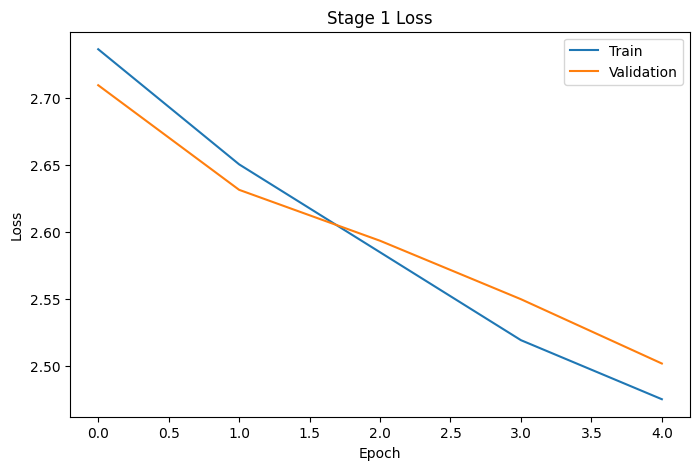

In [75]:
plt.figure(figsize=(8,5))

plt.plot(train_losses,label="Train")

plt.plot(val_losses,label="Validation")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("Stage 1 Loss")

plt.legend()

plt.show()

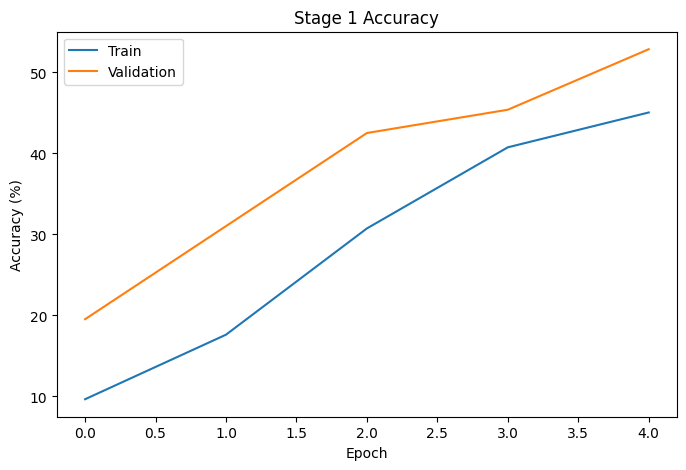

In [76]:
plt.figure(figsize=(8,5))

plt.plot(train_acc,label="Train")

plt.plot(val_acc,label="Validation")

plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.title("Stage 1 Accuracy")

plt.legend()

plt.show()

In [77]:
print("="*60)

print("Stage 1 Completed Successfully")

print("Best Validation Accuracy :", round(best_accuracy,2),"%")

print("="*60)

Stage 1 Completed Successfully
Best Validation Accuracy : 52.87 %


In [78]:
# Unfreeze only layer4
for param in model.layer4.parameters():
    param.requires_grad = True

# Keep FC layer trainable
for param in model.fc.parameters():
    param.requires_grad = True

print("Layer4 and FC are now trainable.")

Layer4 and FC are now trainable.


In [79]:
optimizer = optim.Adam(
    [
        {"params": model.layer4.parameters(), "lr": 1e-5},
        {"params": model.fc.parameters(), "lr": 1e-5}
    ]
)

print("Fine-tuning optimizer created.")

Fine-tuning optimizer created.


In [80]:
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.1,
    patience=3
)

print("Scheduler Ready")

Scheduler Ready


In [81]:
STAGE2_EPOCHS = 20

patience = 5

counter = 0

best_val_loss = float("inf")

print("Stage 2 Ready")

Stage 2 Ready


In [84]:
for epoch in range(STAGE2_EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion
    )

    val_loss, val_accuracy = validate(
        model,
        valid_loader,
        criterion
    )

    scheduler.step(val_loss)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_acc.append(train_accuracy)
    val_acc.append(val_accuracy)

    print(f"\nEpoch {epoch+1}/{STAGE2_EPOCHS}")

    print(f"Train Loss : {train_loss:.4f}")

    print(f"Validation Loss : {val_loss:.4f}")

    print(f"Train Accuracy : {train_accuracy:.2f}%")

    print(f"Validation Accuracy : {val_accuracy:.2f}%")

    # Save Best Model
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        counter = 0

        torch.save(
            model.state_dict(),
            "best_resnet50.pth"
        )

        print("Best Model Saved")

    else:

        counter += 1

        print(f"Early Stopping Counter : {counter}/{patience}")

    if counter >= patience:

        print("\nEarly Stopping Triggered!")

        break


Epoch 1/20
Train Loss : 1.8956
Validation Loss : 1.9775
Train Accuracy : 56.63%
Validation Accuracy : 57.47%
Best Model Saved

Epoch 2/20
Train Loss : 1.7891
Validation Loss : 1.9238
Train Accuracy : 58.82%
Validation Accuracy : 60.92%
Best Model Saved

Epoch 3/20
Train Loss : 1.6837
Validation Loss : 1.8568
Train Accuracy : 60.65%
Validation Accuracy : 60.34%
Best Model Saved

Epoch 4/20
Train Loss : 1.6364
Validation Loss : 1.8118
Train Accuracy : 61.28%
Validation Accuracy : 63.22%
Best Model Saved

Epoch 5/20
Train Loss : 1.5247
Validation Loss : 1.7042
Train Accuracy : 61.78%
Validation Accuracy : 66.09%
Best Model Saved

Epoch 6/20
Train Loss : 1.4386
Validation Loss : 1.5797
Train Accuracy : 63.05%
Validation Accuracy : 68.39%
Best Model Saved

Epoch 7/20
Train Loss : 1.3655
Validation Loss : 1.4984
Train Accuracy : 65.51%
Validation Accuracy : 68.39%
Best Model Saved

Epoch 8/20
Train Loss : 1.2926
Validation Loss : 1.4243
Train Accuracy : 66.29%
Validation Accuracy : 69.54%
B

In [85]:
model.load_state_dict(
    torch.load(
        "best_resnet50.pth",
        map_location=device
    )
)

print("Best Model Loaded")

Best Model Loaded


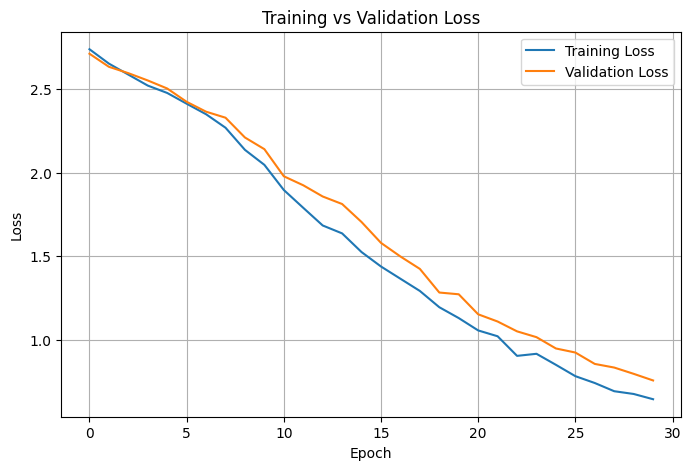

In [86]:
plt.figure(figsize=(8,5))

plt.plot(train_losses, label="Training Loss")

plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("Training vs Validation Loss")

plt.legend()

plt.grid(True)

plt.show()

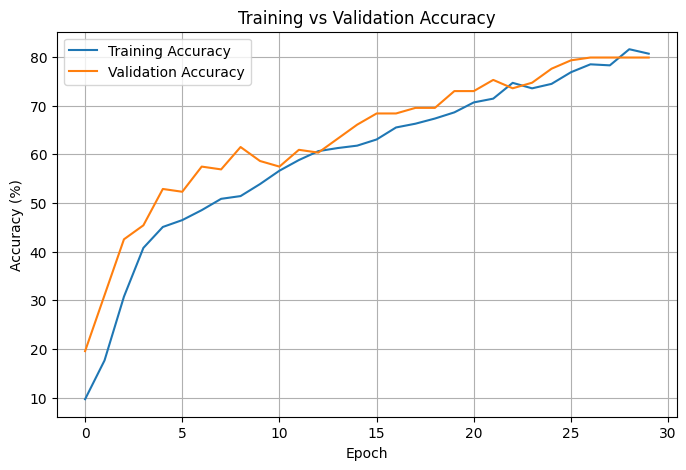

In [87]:
plt.figure(figsize=(8,5))

plt.plot(train_acc, label="Training Accuracy")

plt.plot(val_acc, label="Validation Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.title("Training vs Validation Accuracy")

plt.legend()

plt.grid(True)

plt.show()

In [88]:
print("="*60)

print("Training Completed Successfully")

print(f"Best Validation Loss : {best_val_loss:.4f}")

print(f"Final Validation Accuracy : {max(val_acc):.2f}%")

print("="*60)

print("Files Generated:")

print("✔ best_resnet50.pth")

print("✔ training_history.csv")

Training Completed Successfully
Best Validation Loss : 0.7580
Final Validation Accuracy : 79.89%
Files Generated:
✔ best_resnet50.pth
✔ training_history.csv
